# Local-awareness SIS models on Chung-Lu hypergraphs

This notebook compares the final/metastable epidemic size of the three local-awareness models

$$
M_S:(\alpha_S,\alpha_I)=(1,0),\qquad
M_I:(\alpha_S,\alpha_I)=(0,1),\qquad
M_{SI}:(\alpha_S,\alpha_I)=(1,1).
$$

It performs three analyses:

1. final epidemic size versus the Chung-Lu exponent $\gamma\in[2,4]$ at $N=10^3$;
2. finite-size scaling $\mathbb{E}[I_\infty(N)]\sim N^{d_f}$ and comparison of the fitted fractal dimensions;
3. mean stationary infection density conditioned on vertex hyperdegree at $N=10^3$.

The simulation uses the vectorized tau-leap Markov approximation implemented in `hypergraph_epidemics.py`. Parallelization is over independent graph/sample/model/parameter jobs.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODULE = Path("hypergraph_epidemics.py")
if not MODULE.exists():
    raise FileNotFoundError(
        "Put hypergraph_epidemics.py in the same directory as this notebook."
    )

from hypergraph_epidemics import SISConfig, run_sweep, fit_fractal_dimension

plt.rcParams["figure.figsize"] = (7.2, 4.6)
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 50)

In [2]:
SAVE_DIR='/scratch/kolokcse/logs_awareness_hypergraph/'

## Experiment settings

`N_FINAL = 1000` is used for the direct comparison and degree-conditioned prevalence. Fractal dimension cannot be estimated from a single network size, so it is fitted over `SCALING_SIZES` while retaining \(N=1000\) in that sequence.

The default is 20 independent hypergraph/process samples per parameter combination. For a quick test, set `SAMPLES = 2`, `T_MAX = 10`, and use fewer gamma values.

In [3]:
np.linspace(2.4, 4.0, 9)

array([2.4, 2.6, 2.8, 3. , 3.2, 3.4, 3.6, 3.8, 4. ])

In [4]:
GAMMAS = np.linspace(2.4, 4.0, 9)
N_FINAL = 10**4
SCALING_SIZES = [int(10**3.5),int(10**3.75),int(10**4), int(10**4.25),int(10**4.5)]
SAMPLES = 20
WORKERS = max(1, (os.cpu_count() or 2) - 1)
MASTER_SEED = 20261009

MEAN_HYPERDEGREE = 6.0
HYPEREDGE_SIZE = 5

BETA = 0.4
MU = 0.2
AWARENESS_STRENGTH = 1.0
SYNERGY = 1.0
DT = 0.02
T_MAX = 500.0
BURN_IN_FRACTION = 0.5
INITIAL_FRACTION = 0.1

MODELS = {
    "M_S":  {"alpha_s": 1.0, "alpha_i": 0.0},
    "M_I":  {"alpha_s": 0.0, "alpha_i": 1.0},
    "M_SI": {"alpha_s": 1.0, "alpha_i": 1.0},
}

# ============================================================
# Colors
# ============================================================

def inter_from_256(x):
    return np.interp(
        x=x,
        xp=[0, 255],
        fp=[0, 1],
    )


S_color = (
    inter_from_256(231),
    inter_from_256(197),
    inter_from_256(108),
)

I_color = (
    inter_from_256(189),
    inter_from_256(108),
    inter_from_256(78),
)

SI_color = (
    inter_from_256(86),
    inter_from_256(141),
    inter_from_256(162),
)

colors = [
    S_color,
    I_color,
    SI_color,
]

COLORS = {
    "M_S": S_color,
    "M_I": I_color,
    "M_SI": SI_color,
}

MARKERS = {
    "M_S": "o",
    "M_I": "s",
    "M_SI": "^",
}


print(f"Parallel workers: {WORKERS}")
print(f"Final-size jobs: {len(GAMMAS) * SAMPLES * len(MODELS)}")
print(f"Scaling jobs: {len(GAMMAS) * len(SCALING_SIZES) * SAMPLES * len(MODELS)}")

Parallel workers: 255
Final-size jobs: 540
Scaling jobs: 2700


In [5]:
def make_config(alpha_s, alpha_i):
    return SISConfig(
        beta=BETA,
        mu=MU,
        alpha_s=alpha_s,
        alpha_i=alpha_i,
        awareness_strength=AWARENESS_STRENGTH,
        synergy=SYNERGY,
        dt=DT,
        t_max=T_MAX,
        record_every=10,
        initial_fraction=INITIAL_FRACTION,
        quasi_stationary=True,
        burn_in_fraction=BURN_IN_FRACTION,
    )


def run_models(network_sizes, output_stem):
    all_summary = []
    all_nodes = []

    for model_index, (model_name, awareness) in enumerate(MODELS.items()):
        config = make_config(**awareness)
        prefix = f"{output_stem}_{model_name}"

        summary, nodes = run_sweep(
            model="chung_lu",
            method="monte_carlo",
            network_sizes=network_sizes,
            samples=SAMPLES,
            graph_params={
                "mean_degree": MEAN_HYPERDEGREE,
                "edge_size": HYPEREDGE_SIZE,
            },
            sis_config=config,
            sweep={"gamma": GAMMAS},
            workers=WORKERS,
            seed=MASTER_SEED + 100000 * model_index,
            output_prefix=prefix,
        )

        summary["awareness_model"] = model_name
        nodes["awareness_model"] = model_name
        all_summary.append(summary)
        all_nodes.append(nodes)

    summary = pd.concat(all_summary, ignore_index=True)
    nodes = pd.concat(all_nodes, ignore_index=True)
    summary.to_csv(f"{output_stem}_all_summary.csv", index=False)
    nodes.to_csv(f"{output_stem}_all_nodes.csv", index=False)
    return summary, nodes

## 1. Final epidemic size at $N=10^4$

The reported final size is the mean recorded number of infected vertices over the second half of each trajectory. With `quasi_stationary=True`, extinction is followed by reinfection of one random vertex, so this is a quasi-stationary approximation rather than an absorbing-state average.

In [30]:
final_summary, final_nodes = run_models(
    network_sizes=[N_FINAL],
    output_stem=SAVE_DIR+"results_final_N1000",
)

final_stats = (
    final_summary
    .groupby(["awareness_model", "gamma"], as_index=False)
    .agg(
        mean_I=("stationary_I", "mean"),
        sem_I=("stationary_I", "sem"),
        mean_density=("stationary_density", "mean"),
        sem_density=("stationary_density", "sem"),
        samples=("stationary_I", "size"),
    )
)
final_stats.to_csv(SAVE_DIR+"final_epidemic_comparison_N1000.csv", index=False)
final_stats

,awareness_model,gamma,mean_I,sem_I,mean_density,sem_density,samples
0,M_I,2.4,729.103877,25.622709,0.072910,0.002562,20
1,M_I,2.6,1267.402158,19.200723,0.126740,0.001920,20
2,M_I,2.8,1687.169984,17.813315,0.168717,0.001781,20
3,M_I,3.0,1958.642686,15.226477,0.195864,0.001523,20
4,M_I,3.2,2156.400600,11.386667,0.215640,0.001139,20
5,M_I,3.4,2324.894005,6.780917,0.232489,0.000678,20
6,M_I,3.6,2447.822262,5.323012,0.244782,0.000532,20
7,M_I,3.8,2526.246403,4.746603,0.252625,0.000475,20
8,M_I,4.0,2603.754077,5.590114,0.260375,0.000559,20
9,M_S,2.4,3012.735532,7.649142,0.301274,0.000765,20


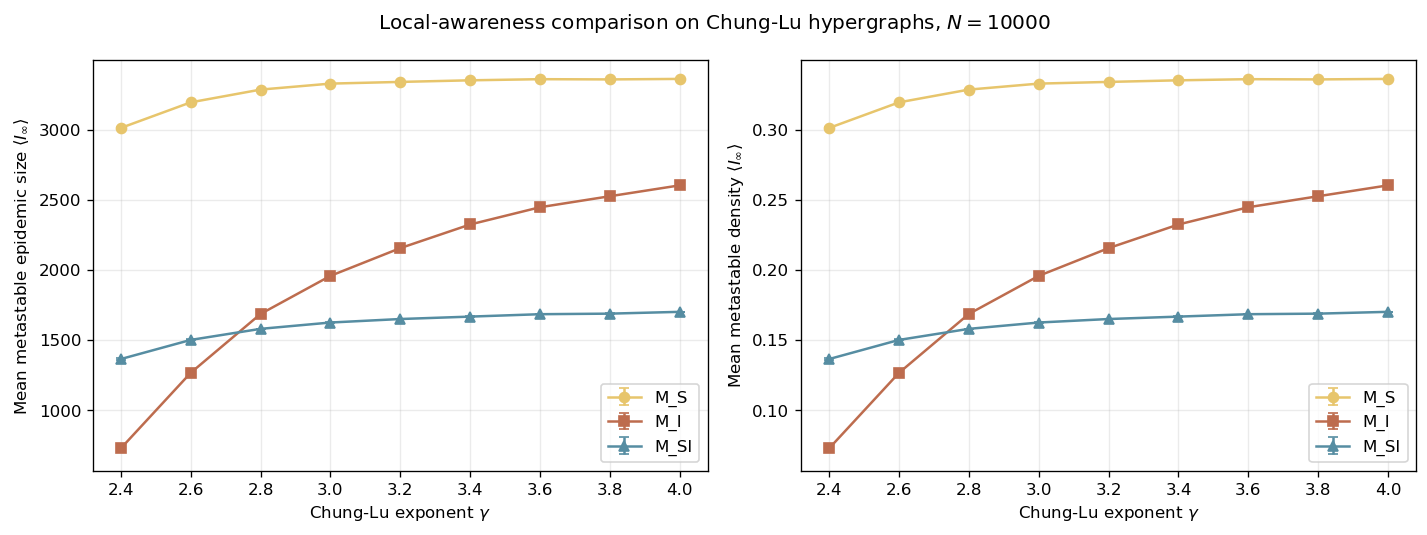

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.5), sharex=True)

for model_name in MODELS:
    d = final_stats[final_stats["awareness_model"] == model_name]
    axes[0].errorbar(
        d["gamma"], d["mean_I"], yerr=d["sem_I"],
        marker=MARKERS[model_name], color=COLORS[model_name],
        capsize=3, label=model_name,
    )
    axes[1].errorbar(
        d["gamma"], d["mean_density"], yerr=d["sem_density"],
        marker=MARKERS[model_name], color=COLORS[model_name],
        capsize=3, label=model_name,
    )

axes[0].set_ylabel(r"Mean metastable epidemic size $\langle I_\infty \rangle$")
axes[1].set_ylabel(r"Mean metastable density $\langle I_\infty \rangle$")
for ax in axes:
    ax.set_xlabel(r"Chung-Lu exponent $\gamma$")
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle(rf"Local-awareness comparison on Chung-Lu hypergraphs, $N={N_FINAL}$")
fig.tight_layout()
fig.savefig("final_epidemic_size_vs_gamma_N1000.pdf", bbox_inches="tight")
fig.savefig("final_epidemic_size_vs_gamma_N1000.png", dpi=250, bbox_inches="tight")
plt.show()

## 2. Fractal-dimension comparison

For each awareness model and gamma value, the notebook averages over samples at each size and fits

$$
\log \mathbb{E}[I_\infty(N)] = c + d_f\log N.
$$

A meaningful fit requires multiple network sizes. The reported \(R^2\) should be inspected together with the slope. If the log-log relationship is visibly curved, expand the size range or report an effective finite-size exponent rather than an asymptotic fractal dimension.

In [6]:
scaling_summary, scaling_nodes = run_models(
    network_sizes=SCALING_SIZES,
    output_stem=SAVE_DIR + "results_fractal_scaling",
)

fractal_parts = []
for model_name in MODELS:
    d = scaling_summary[scaling_summary["awareness_model"] == model_name]
    fit = fit_fractal_dimension(d, group_by=["gamma"], response="stationary_I")
    fit["awareness_model"] = model_name
    fractal_parts.append(fit)

fractal = pd.concat(fractal_parts, ignore_index=True)
fractal.to_csv(SAVE_DIR+"fractal_dimension_comparison.csv", index=False)
fractal

,gamma,fractal_dimension,intercept,r2,points,awareness_model
0,2.4,0.990675,-1.119808,0.999995,5,M_S
1,2.6,0.999342,-1.134521,0.999999,5,M_S
2,2.8,0.999844,-1.111877,0.999998,5,M_S
3,3.0,1.000147,-1.101483,1.000000,5,M_S
4,3.2,1.001259,-1.106824,0.999999,5,M_S
5,3.4,1.000289,-1.095390,1.000000,5,M_S
6,3.6,0.999910,-1.090190,1.000000,5,M_S
7,3.8,1.000689,-1.097553,0.999999,5,M_S
8,4.0,1.000202,-1.092590,1.000000,5,M_S
9,2.4,0.890953,-1.608223,0.998399,5,M_I


In [3]:
scaling_summary=pd.read_csv(SAVE_DIR+"fractal_dimension_comparison.csv")

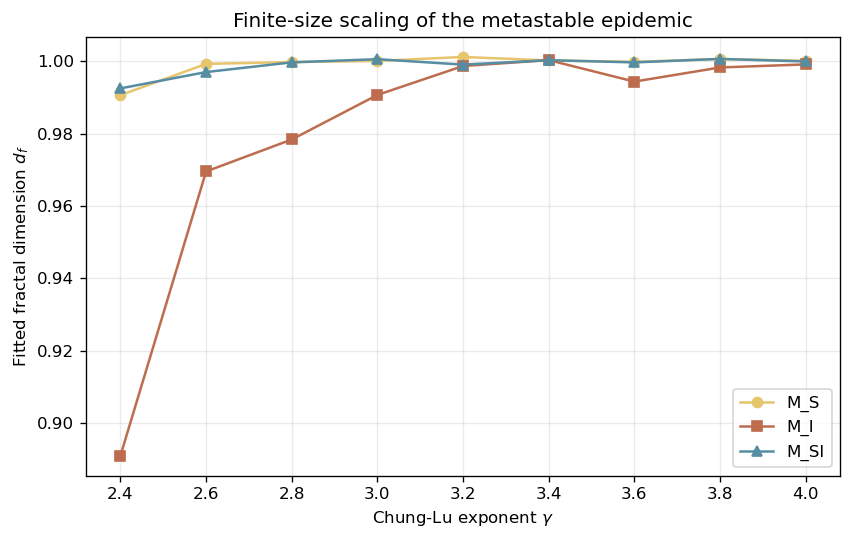

In [7]:
fig, ax = plt.subplots()
for model_name in MODELS:
    d = fractal[fractal["awareness_model"] == model_name]
    ax.plot(
        d["gamma"], d["fractal_dimension"],
        marker=MARKERS[model_name], color=COLORS[model_name], label=model_name,
    )

ax.set_xlabel(r"Chung-Lu exponent $\gamma$")
ax.set_ylabel(r"Fitted fractal dimension $d_f$")
ax.set_title(r"Finite-size scaling of the metastable epidemic")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("fractal_dimension_vs_gamma.pdf", bbox_inches="tight")
fig.savefig("fractal_dimension_vs_gamma.png", dpi=250, bbox_inches="tight")
plt.show()

In [11]:
raw_scaling_summary = pd.read_csv(SAVE_DIR+
    "results_fractal_scaling_all_summary.csv"
)

final_nodes=pd.read_csv(SAVE_DIR+"results_final_N1000_all_nodes.csv")

print(raw_scaling_summary.columns.tolist())

['method', 'model', 'n', 'sample', 'seed', 'gamma', 'stationary_I', 'stationary_density', 'awareness_model']


In [12]:
raw_scaling_summary.head()

,method,model,n,sample,seed,gamma,stationary_I,stationary_density,awareness_model
0,monte_carlo,chung_lu,3162,0,930026932,2.4,959.707434,0.303513,M_S
1,monte_carlo,chung_lu,3162,1,1566963252,2.4,974.762590,0.308274,M_S
2,monte_carlo,chung_lu,3162,2,465859122,2.4,937.004796,0.296333,M_S
3,monte_carlo,chung_lu,3162,3,4127385812,2.4,963.926459,0.304847,M_S
4,monte_carlo,chung_lu,3162,4,1105978535,2.4,969.258193,0.306533,M_S


In [9]:
from scipy.stats import t




# ============================================================
# Bootstrap confidence intervals for the fractal dimensions
# ============================================================

def bootstrap_fractal_dimensions(
    data,
    n_bootstrap=2000,
    confidence_level=0.95,
    seed=20261011,
):
    """
    Estimate fractal dimensions and bootstrap confidence intervals.

    For each awareness model and gamma:
      1. resample simulations independently within every network size;
      2. calculate the resampled mean epidemic size at each N;
      3. fit log(mean I) against log(N);
      4. repeat the procedure n_bootstrap times.
    """

    rng = np.random.default_rng(seed)

    alpha = 1.0 - confidence_level

    rows = []

    for model_name in MODELS:

        model_data = data[
            data["awareness_model"] == model_name
        ]

        for gamma in np.sort(
            model_data["gamma"].unique()
        ):

            gamma_data = model_data[
                np.isclose(
                    model_data["gamma"],
                    gamma,
                )
            ]

            network_sizes = np.sort(
                gamma_data["n"].unique()
            )

            mean_epidemic_sizes = (
                gamma_data
                .groupby("n")["stationary_I"]
                .mean()
                .reindex(network_sizes)
                .to_numpy()
            )

            valid = mean_epidemic_sizes > 0

            fitted_sizes = network_sizes[valid]
            fitted_epidemics = mean_epidemic_sizes[valid]

            if len(fitted_sizes) < 2:
                continue

            point_slope, point_intercept = np.polyfit(
                np.log(fitted_sizes),
                np.log(fitted_epidemics),
                1,
            )

            bootstrap_slopes = []

            for _ in range(n_bootstrap):

                bootstrap_means = []

                for n in fitted_sizes:

                    values = gamma_data.loc[
                        gamma_data["n"] == n,
                        "stationary_I",
                    ].to_numpy()

                    sampled_values = rng.choice(
                        values,
                        size=len(values),
                        replace=True,
                    )

                    bootstrap_means.append(
                        sampled_values.mean()
                    )

                bootstrap_means = np.asarray(
                    bootstrap_means
                )

                if np.any(bootstrap_means <= 0):
                    continue

                bootstrap_slope, _ = np.polyfit(
                    np.log(fitted_sizes),
                    np.log(bootstrap_means),
                    1,
                )

                bootstrap_slopes.append(
                    bootstrap_slope
                )

            bootstrap_slopes = np.asarray(
                bootstrap_slopes
            )

            lower = np.quantile(
                bootstrap_slopes,
                alpha / 2.0,
            )

            upper = np.quantile(
                bootstrap_slopes,
                1.0 - alpha / 2.0,
            )

            rows.append(
                {
                    "awareness_model": model_name,
                    "gamma": gamma,
                    "fractal_dimension": point_slope,
                    "intercept": point_intercept,
                    "ci_lower": lower,
                    "ci_upper": upper,
                    "bootstrap_standard_error":
                        bootstrap_slopes.std(ddof=1),
                    "bootstrap_samples":
                        len(bootstrap_slopes),
                }
            )

    return pd.DataFrame(rows)


fractal_ci = bootstrap_fractal_dimensions(
    scaling_summary,
    n_bootstrap=2000,
    confidence_level=0.95,
    seed=20261011,
)

fractal_ci

,awareness_model,gamma,fractal_dimension,intercept,ci_lower,ci_upper,bootstrap_standard_error,bootstrap_samples
0,M_S,2.4,0.990675,-1.119808,0.987265,0.994430,0.001838,2000
1,M_S,2.6,0.999342,-1.134521,0.997929,1.000813,0.000754,2000
2,M_S,2.8,0.999844,-1.111877,0.998800,1.000893,0.000531,2000
3,M_S,3.0,1.000147,-1.101483,0.999158,1.001183,0.000526,2000
4,M_S,3.2,1.001259,-1.106824,1.000609,1.001947,0.000341,2000
5,M_S,3.4,1.000289,-1.095390,0.999515,1.000939,0.000357,2000
6,M_S,3.6,0.999910,-1.090190,0.999320,1.000521,0.000304,2000
7,M_S,3.8,1.000689,-1.097553,0.999893,1.001445,0.000392,2000
8,M_S,4.0,1.000202,-1.092590,0.999516,1.000886,0.000349,2000
9,M_I,2.4,0.890953,-1.608223,0.854050,0.930511,0.019732,2000


In [13]:
# ============================================================
# Logarithmically binned degree prevalence for gamma near 2.3
# ============================================================

TARGET_GAMMA = 2.3
NUMBER_OF_DEGREE_BINS = 14

available_gammas = np.sort(
    final_nodes["gamma"].unique()
)

selected_gamma = available_gammas[
    np.argmin(
        np.abs(
            available_gammas
            - TARGET_GAMMA
        )
    )
]

print(
    f"Requested gamma: {TARGET_GAMMA:.3f}"
)

print(
    f"Selected available gamma: {selected_gamma:.6f}"
)


selected_nodes = final_nodes[
    np.isclose(
        final_nodes["gamma"],
        selected_gamma,
    )
].copy()

selected_nodes = selected_nodes[
    selected_nodes["degree"] > 0
].copy()


# Common logarithmic bins for all three awareness models
minimum_degree = selected_nodes["degree"].min()
maximum_degree = selected_nodes["degree"].max()

degree_bin_edges = np.unique(
    np.geomspace(
        minimum_degree,
        maximum_degree + 1,
        NUMBER_OF_DEGREE_BINS + 1,
    ).astype(int)
)

selected_nodes["degree_bin"] = pd.cut(
    selected_nodes["degree"],
    bins=degree_bin_edges,
    include_lowest=True,
    right=False,
)


# First average within each independent simulation.
# This prevents degree classes containing many vertices from being
# treated as if every vertex were an independent Monte Carlo sample.
sample_degree_prevalence = (
    selected_nodes
    .groupby(
        [
            "awareness_model",
            "sample",
            "degree_bin",
        ],
        observed=True,
        as_index=False,
    )
    .agg(
        mean_degree=(
            "degree",
            "mean",
        ),
        sample_prevalence=(
            "prevalence",
            "mean",
        ),
        vertices_in_bin=(
            "prevalence",
            "size",
        ),
    )
)


# Then calculate statistics across independent simulations.
degree_ci = (
    sample_degree_prevalence
    .groupby(
        [
            "awareness_model",
            "degree_bin",
        ],
        observed=True,
        as_index=False,
    )
    .agg(
        mean_degree=(
            "mean_degree",
            "mean",
        ),
        mean_prevalence=(
            "sample_prevalence",
            "mean",
        ),
        sem_prevalence=(
            "sample_prevalence",
            "sem",
        ),
        number_of_samples=(
            "sample_prevalence",
            "size",
        ),
        total_vertices=(
            "vertices_in_bin",
            "sum",
        ),
    )
)


degree_ci["t_critical"] = t.ppf(
    0.975,
    degree_ci["number_of_samples"] - 1,
)

degree_ci["ci_half_width"] = (
    degree_ci["t_critical"]
    * degree_ci["sem_prevalence"]
)

degree_ci["ci_lower"] = np.maximum(
    degree_ci["mean_prevalence"]
    - degree_ci["ci_half_width"],
    0.0,
)

degree_ci["ci_upper"] = np.minimum(
    degree_ci["mean_prevalence"]
    + degree_ci["ci_half_width"],
    1.0,
)

degree_ci.to_csv(
    "degree_prevalence_gamma_2_3_with_95CI.csv",
    index=False,
)

degree_ci.head()

Requested gamma: 2.300
Selected available gamma: 2.400000


,awareness_model,degree_bin,mean_degree,mean_prevalence,sem_prevalence,number_of_samples,total_vertices,t_critical,ci_half_width,ci_lower,ci_upper
0,M_I,"[1, 2)",1.000000,0.016103,0.000517,20,28579,2.093024,0.001082,0.015021,0.017185
1,M_I,"[2, 4)",2.474104,0.040748,0.001499,20,68105,2.093024,0.003138,0.037609,0.043886
2,M_I,"[4, 7)",4.749680,0.075202,0.002595,20,51913,2.093024,0.005431,0.069771,0.080634
3,M_I,"[7, 13)",8.702356,0.125857,0.004034,20,24755,2.093024,0.008443,0.117415,0.134300
4,M_I,"[13, 22)",15.998152,0.205588,0.005805,20,7826,2.093024,0.012151,0.193438,0.217739


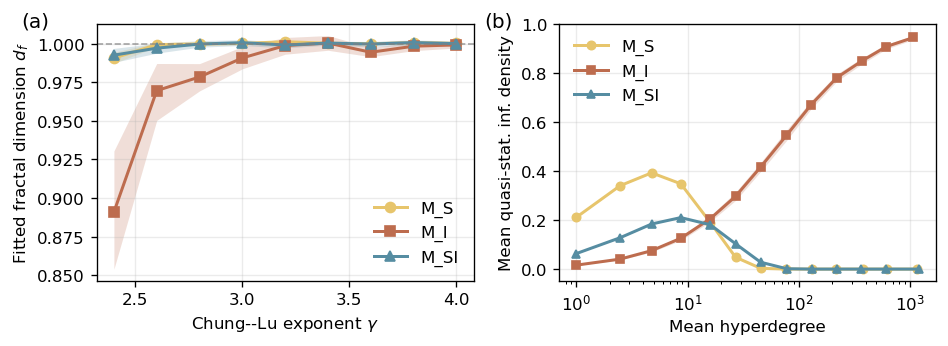

In [14]:
# ============================================================
# Combined two-panel figure
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(8, 3),
)


# ------------------------------------------------------------
# Panel (a): fractal dimension with bootstrap 95% CI
# ------------------------------------------------------------

for model_name in MODELS:

    d = (
        fractal_ci[
            fractal_ci["awareness_model"]
            == model_name
        ]
        .sort_values("gamma")
        .copy()
    )

    axes[0].plot(
        d["gamma"],
        d["fractal_dimension"],
        marker=MARKERS[model_name],
        color=COLORS[model_name],
        linewidth=1.8,
        markersize=6,
        label=model_name,
    )

    axes[0].fill_between(
        d["gamma"],
        d["ci_lower"],
        d["ci_upper"],
        color=COLORS[model_name],
        alpha=0.22,
        linewidth=0,
    )


axes[0].set_xlabel(
    r"Chung--Lu exponent $\gamma$"
)

axes[0].set_ylabel(
    r"Fitted fractal dimension $d_f$"
)

axes[0].grid(
    alpha=0.25
)

axes[0].legend(
    frameon=False
)


# Optional reference line for extensive scaling
axes[0].axhline(
    1.0,
    color="grey",
    linestyle="--",
    linewidth=1.0,
    alpha=0.7,
)


# ------------------------------------------------------------
# Panel (b): prevalence by log-binned hyperdegree
# ------------------------------------------------------------

for model_name in MODELS:

    d = (
        degree_ci[
            degree_ci["awareness_model"]
            == model_name
        ]
        .sort_values("mean_degree")
        .copy()
    )

    # Retain bins represented in at least two independent samples.
    d = d[
        d["number_of_samples"] >= 2
    ]

    axes[1].plot(
        d["mean_degree"],
        d["mean_prevalence"],
        marker=MARKERS[model_name],
        color=COLORS[model_name],
        linewidth=1.8,
        markersize=5,
        label=model_name,
    )

    axes[1].fill_between(
        d["mean_degree"],
        d["ci_lower"],
        d["ci_upper"],
        color=COLORS[model_name],
        alpha=0.22,
        linewidth=0,
    )


axes[1].set_xscale(
    "log"
)

axes[1].set_xlabel(
    "Mean hyperdegree"
)

axes[1].set_ylabel(
    "Mean quasi-stat. inf. density"
)

axes[1].grid(
    alpha=0.25
)

# panel labels
axes[0].text(
    -0.2, 1.05, "(a)",
    transform=axes[0].transAxes,
    va="top",
    fontsize=12,
)

axes[1].text(
    -0.2, 1.05, "(b)",
    transform=axes[1].transAxes,
    va="top",
    fontsize=12,
)

axes[1].legend(
    frameon=False
)


# ------------------------------------------------------------
# Final formatting
# ------------------------------------------------------------

fig.tight_layout()

fig.savefig(
    "fractal_dimension_and_degree_density.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "fractal_dimension_and_degree_density.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

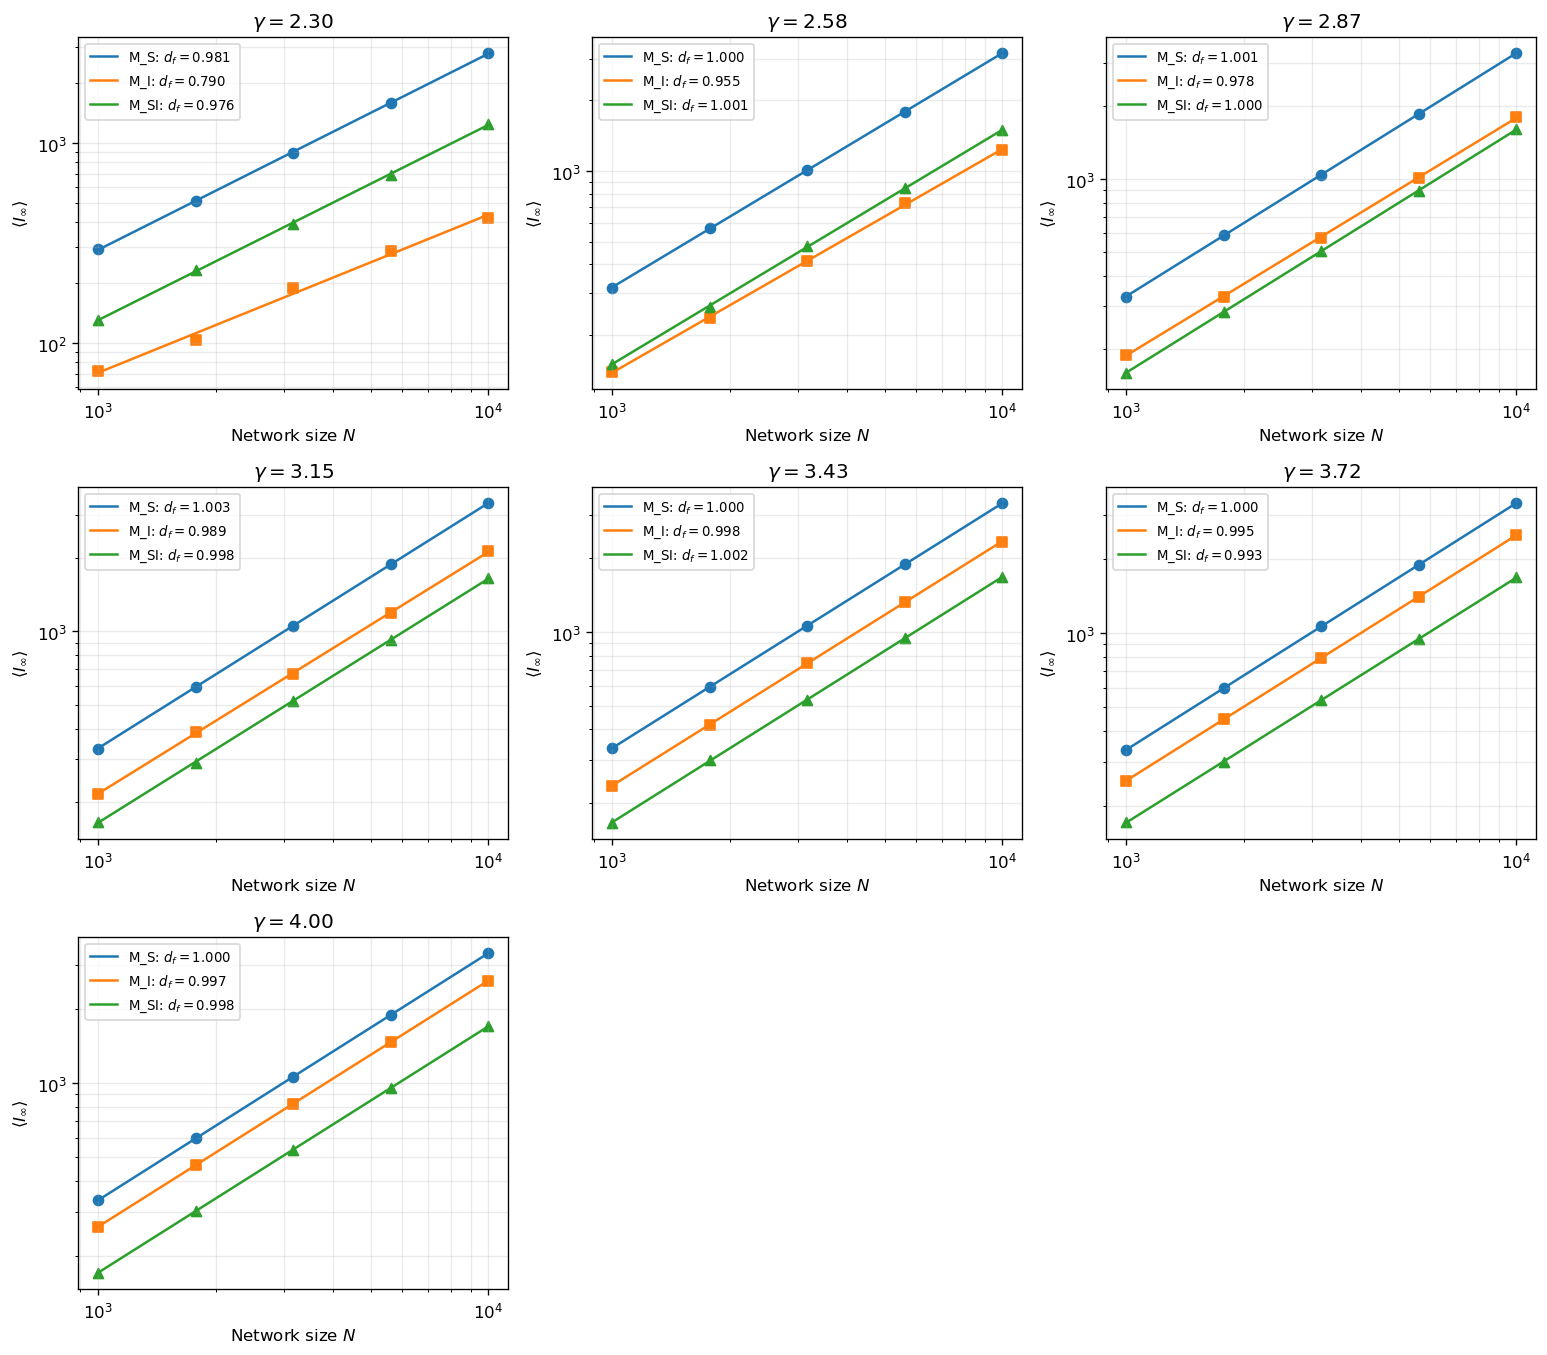

In [22]:
# Diagnostic log-log panels with fitted lines.
ncols = 3
nrows = int(np.ceil(len(GAMMAS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.8 * nrows), squeeze=False)

for ax, gamma in zip(axes.ravel(), GAMMAS):
    for model_name in MODELS:
        d = scaling_summary[
            (scaling_summary["awareness_model"] == model_name)
            & np.isclose(scaling_summary["gamma"], gamma)
        ]
        avg = d.groupby("n", as_index=False)["stationary_I"].mean()
        fit = fractal[
            (fractal["awareness_model"] == model_name)
            & np.isclose(fractal["gamma"], gamma)
        ].iloc[0]

        ax.scatter(
            avg["n"], avg["stationary_I"],
            marker=MARKERS[model_name], color=COLORS[model_name],
        )
        n_line = np.geomspace(avg["n"].min(), avg["n"].max(), 100)
        i_line = np.exp(fit["intercept"]) * n_line ** fit["fractal_dimension"]
        ax.plot(
            n_line, i_line, color=COLORS[model_name],
            label=rf"{model_name}: $d_f={fit['fractal_dimension']:.3f}$",
        )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(rf"$\gamma={gamma:.2f}$")
    ax.set_xlabel(r"Network size $N$")
    ax.set_ylabel(r"$\langle I_\infty \rangle$")
    ax.grid(alpha=0.25, which="both")
    ax.legend(fontsize=8)

for ax in axes.ravel()[len(GAMMAS):]:
    ax.set_visible(False)

fig.tight_layout()
fig.savefig("fractal_loglog_diagnostics.pdf", bbox_inches="tight")
fig.savefig("fractal_loglog_diagnostics.png", dpi=250, bbox_inches="tight")
plt.show()

## 3. Mean stationary infection density by hyperdegree

Exact degree classes in the tail may contain very few vertices. The notebook therefore shows only classes with at least `MIN_OBSERVATIONS` vertex observations across samples. For very heavy-tailed cases, the optional logarithmic-binning section gives a more stable summary.

In [23]:
MIN_OBSERVATIONS = 20

degree_stats = (
    final_nodes
    .groupby(["awareness_model", "gamma", "degree"], as_index=False)
    .agg(
        mean_prevalence=("prevalence", "mean"),
        sem_prevalence=("prevalence", "sem"),
        observations=("prevalence", "size"),
    )
)
degree_stats.to_csv(SAVE_DIR+"degree_conditioned_prevalence_N1000.csv", index=False)
degree_stats.head()

,awareness_model,gamma,degree,mean_prevalence,sem_prevalence,observations
0,M_I,2.3,0,0.000000,0.000000,17015
1,M_I,2.3,1,0.010169,0.000246,34259
2,M_I,2.3,2,0.019280,0.000322,37773
3,M_I,2.3,3,0.028872,0.000429,30700
4,M_I,2.3,4,0.039015,0.000598,21664


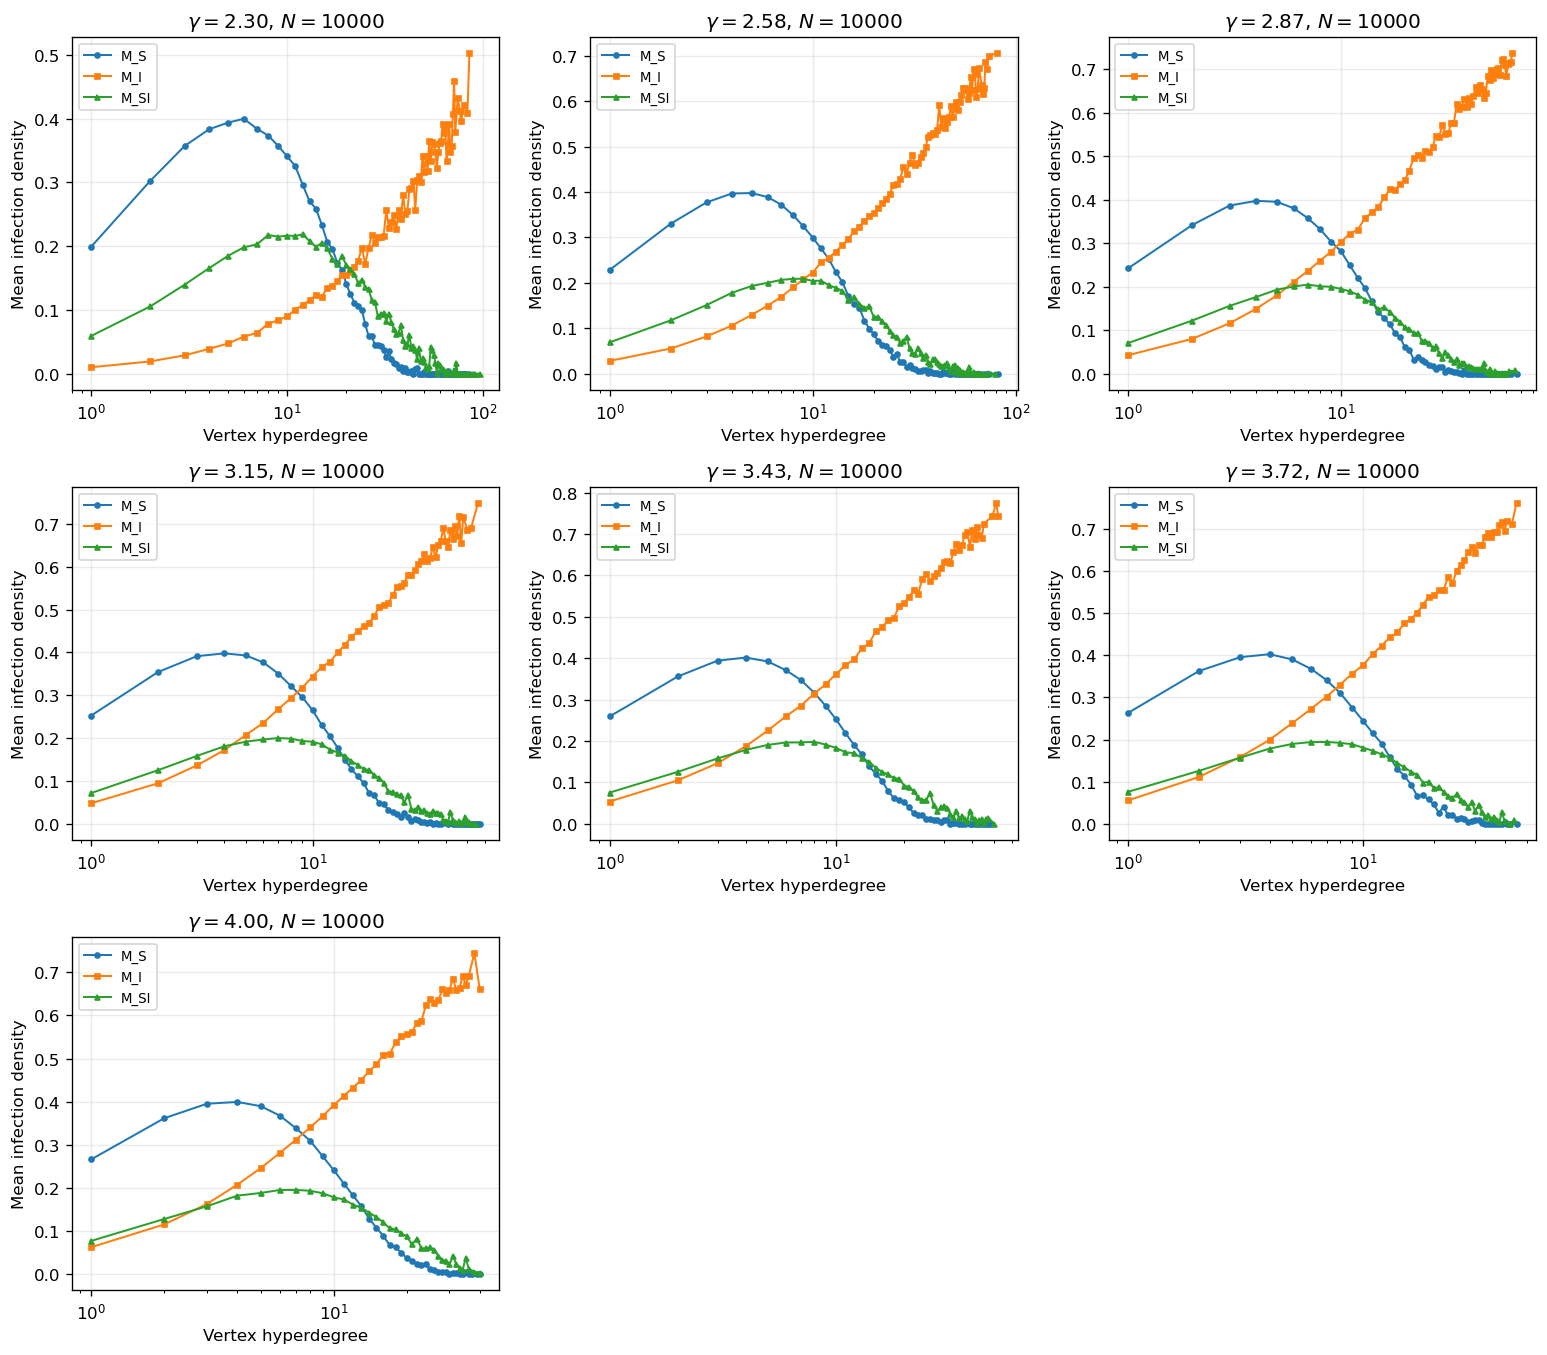

In [24]:
ncols = 3
nrows = int(np.ceil(len(GAMMAS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.8 * nrows), squeeze=False)

for ax, gamma in zip(axes.ravel(), GAMMAS):
    for model_name in MODELS:
        d = degree_stats[
            (degree_stats["awareness_model"] == model_name)
            & np.isclose(degree_stats["gamma"], gamma)
            & (degree_stats["observations"] >= MIN_OBSERVATIONS)
            & (degree_stats["degree"] > 0)
        ]
        ax.plot(
            d["degree"], d["mean_prevalence"],
            marker=MARKERS[model_name], markersize=3,
            linewidth=1.2, color=COLORS[model_name], label=model_name,
        )

    ax.set_xscale("log")
    ax.set_xlabel("Vertex hyperdegree")
    ax.set_ylabel("Mean infection density")
    ax.set_title(rf"$\gamma={gamma:.2f}$, $N={N_FINAL}$")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

for ax in axes.ravel()[len(GAMMAS):]:
    ax.set_visible(False)

fig.tight_layout()
fig.savefig("degree_prevalence_all_gammas_N1000.pdf", bbox_inches="tight")
fig.savefig("degree_prevalence_all_gammas_N1000.png", dpi=250, bbox_inches="tight")
plt.show()

In [25]:
def logarithmic_degree_bins(nodes, bins=14):
    positive = nodes[nodes["degree"] > 0].copy()
    k_min = positive["degree"].min()
    k_max = positive["degree"].max()
    edges = np.unique(np.geomspace(k_min, k_max + 1, bins + 1).astype(int))
    if len(edges) < 3:
        return pd.DataFrame()

    positive["degree_bin"] = pd.cut(
        positive["degree"], bins=edges, include_lowest=True, right=False
    )
    result = (
        positive
        .groupby(["awareness_model", "gamma", "degree_bin"], observed=True)
        .agg(
            mean_degree=("degree", "mean"),
            mean_prevalence=("prevalence", "mean"),
            sem_prevalence=("prevalence", "sem"),
            observations=("prevalence", "size"),
        )
        .reset_index()
    )
    return result

binned_degree_stats = logarithmic_degree_bins(final_nodes)
binned_degree_stats.to_csv(SAVE_DIR+"degree_prevalence_log_binned_N1000.csv", index=False)
binned_degree_stats.head()

,awareness_model,gamma,degree_bin,mean_degree,mean_prevalence,sem_prevalence,observations
0,M_I,2.3,"[1, 2)",1.000000,0.010169,0.000246,34259
1,M_I,2.3,"[2, 5)",2.821283,0.027290,0.000247,90137
2,M_I,2.3,"[5, 8)",5.748495,0.054455,0.000591,30075
3,M_I,2.3,"[8, 14)",9.815690,0.090914,0.001007,15946
4,M_I,2.3,"[14, 25)",17.775771,0.143975,0.001764,7033


/scratch/kolokcse/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:44: RuntimeWarning: invalid value encountered in reduce
  return umr_minimum(a, axis, None, out, keepdims, initial, where)
/scratch/kolokcse/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:40: RuntimeWarning: invalid value encountered in reduce
  return umr_maximum(a, axis, None, out, keepdims, initial, where)


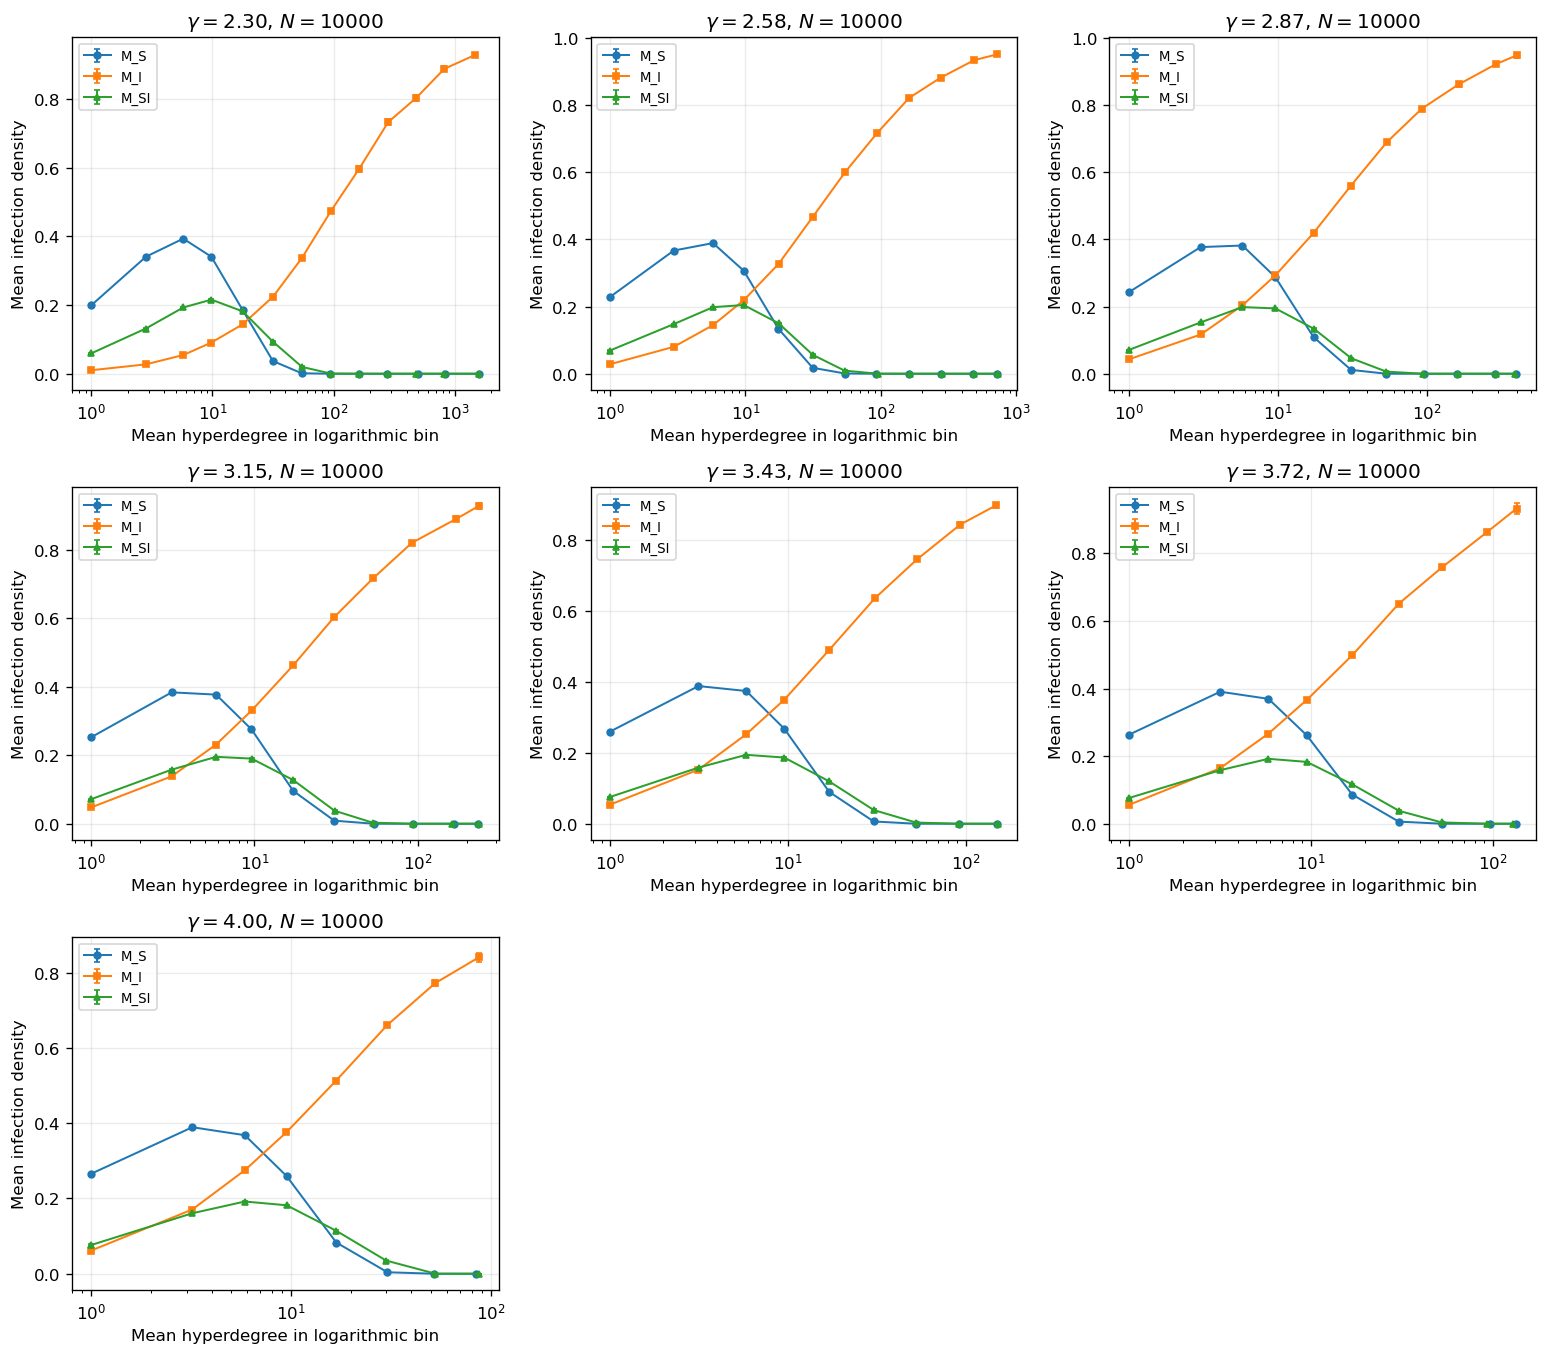

In [26]:
ncols = 3
nrows = int(np.ceil(len(GAMMAS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.8 * nrows), squeeze=False)

for ax, gamma in zip(axes.ravel(), GAMMAS):
    for model_name in MODELS:
        d = binned_degree_stats[
            (binned_degree_stats["awareness_model"] == model_name)
            & np.isclose(binned_degree_stats["gamma"], gamma)
        ]
        ax.errorbar(
            d["mean_degree"], d["mean_prevalence"],
            yerr=d["sem_prevalence"], marker=MARKERS[model_name],
            markersize=4, linewidth=1.2, capsize=2,
            color=COLORS[model_name], label=model_name,
        )

    ax.set_xscale("log")
    ax.set_xlabel("Mean hyperdegree in logarithmic bin")
    ax.set_ylabel("Mean infection density")
    ax.set_title(rf"$\gamma={gamma:.2f}$, $N={N_FINAL}$")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

for ax in axes.ravel()[len(GAMMAS):]:
    ax.set_visible(False)

fig.tight_layout()
fig.savefig("degree_prevalence_log_binned_N1000.pdf", bbox_inches="tight")
fig.savefig("degree_prevalence_log_binned_N1000.png", dpi=250, bbox_inches="tight")
plt.show()

## Interpretation checklist

- Compare `mean_I` and `mean_density` across the three awareness models at fixed gamma.
- The proposed epidemic paradox is supported where \(M_I\) has a smaller epidemic than \(M_{SI}\), with uncertainty bars sufficiently separated or confirmed by a paired/repeated analysis.
- Compare \(d_f\) only when the log-log diagnostic is approximately linear and \(R^2\) is satisfactory.
- In the degree plots, inspect whether \(M_I\) concentrates infection on high-hyperdegree vertices while reducing infection among the numerous low-degree vertices.
- Repeat the experiment for multiple values of `beta`, `awareness_strength`, `edge_size`, and `synergy` before drawing a general conclusion.